# Seminar 1 · Part 3: The Iris flowers

**The story of today** (from the book *Probability and Statistics for Data Science*, section 4.8):

1. **Goal.** Estimate the conditional pmf of the class $\tilde{y}$ given the features $\tilde{x}$: $\;p_{\tilde{y}\mid\tilde{x}}(y \mid x)$. Then predict the most likely class, $\mathrm{MAP}(x) = \arg\max_y p_{\tilde{y}\mid\tilde{x}}(y \mid x)$.
2. **Attempt 1: just count.** $p_{\tilde{y}\mid\tilde{x}}(y \mid x) = p_{\tilde{x},\tilde{y}}(x, y) \,/\, p_{\tilde{x}}(x)$, and count the training examples equal to $x$. It fails: almost every new $x$ was never seen (the **curse of dimensionality**).
3. **Attempt 2: build the joint pmf from small pieces.** With the naive Bayes assumption (the features are conditionally independent given the class):
$$p_{\tilde{y}\mid\tilde{x}}(y \mid x) = \frac{p_{\tilde{y}}(y)\prod_{j=1}^{d} p_{\tilde{x}[j]\mid\tilde{y}}(x[j] \mid y)}{\sum_{k} p_{\tilde{y}}(k)\prod_{j=1}^{d} p_{\tilde{x}[j]\mid\tilde{y}}(x[j] \mid k)}$$
We only need to estimate the prior $p_{\tilde{y}}$ and one small pmf (or pdf) per feature and class.

**scikit-learn** does all the counting and the computing for us. We read what it learned and check it against the slides.

Here: $x$ is the 4 measurements of a flower (in cm), and the class is its species. The features are real numbers, so we use **pdfs** $f$ instead of pmfs for them.

**How to use this notebook:** run the cells one by one from the top, with **Shift + Enter**. Read the text cells: they explain what each code cell does.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris                  # the Iris data comes with scikit-learn
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.naive_bayes import GaussianNB              # naive Bayes with one Gaussian per feature and class
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score

SEED = 0                                                # fixed random seed: everyone gets the same split and the same numbers

## 1. Load the data

In [2]:
iris = load_iris(as_frame=True)
FEATURES = ["sepal length", "sepal width", "petal length", "petal width"]   # all in cm

data = iris.data.copy()
data.columns = FEATURES
data["species"] = iris.target_names[iris.target]
data.index = range(1, 151)                              # number the flowers 1 to 150, as on the slides
data.loc[[1, 51, 101]]

,sepal length,sepal width,petal length,petal width,species
1,5.1,3.5,1.4,0.2,setosa
51,7.0,3.2,4.7,1.4,versicolor
101,6.3,3.3,6.0,2.5,virginica


## 2. Look at the data

### How many flowers of each species? The mean of each feature

In [3]:
print(data["species"].value_counts())
data.groupby("species").mean().round(2)

species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


,sepal length,sepal width,petal length,petal width
species,,,,
setosa,5.01,3.43,1.46,0.25
versicolor,5.94,2.77,4.26,1.33
virginica,6.59,2.97,5.55,2.03


### All pairs of features, in one picture

On the diagonal: the distribution of each feature, for each species. Elsewhere: one feature against another.

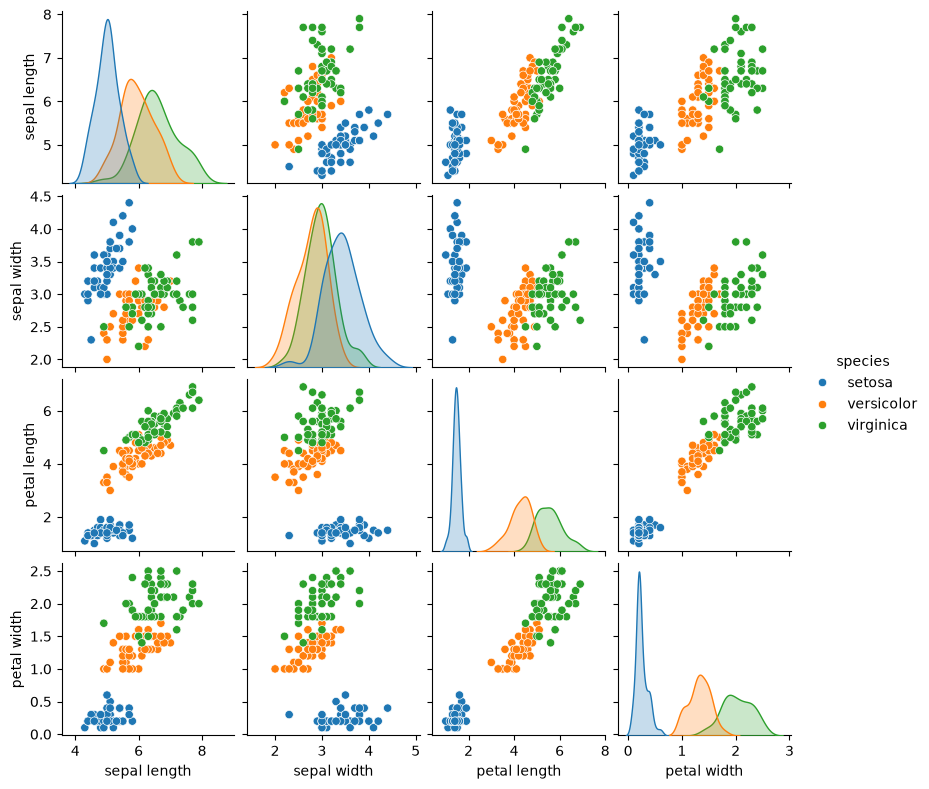

In [4]:
sns.pairplot(data, hue="species", height=2)
plt.show()

### Are the features independent? Correlation matrices

A correlation far from 0 means: **not** independent. The naive Bayes assumption is about **one species at a time**, so look at one species.

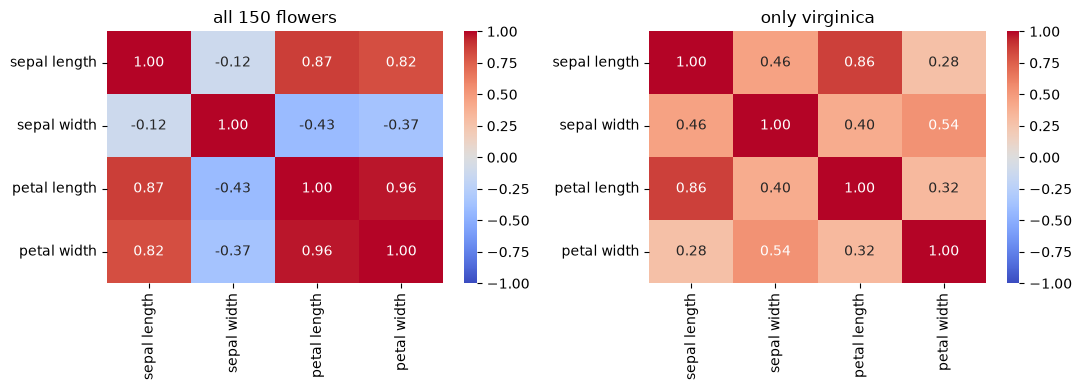

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.heatmap(data[FEATURES].corr(), annot=True, fmt=".2f", vmin=-1, vmax=1, cmap="coolwarm", ax=axes[0])
axes[0].set_title("all 150 flowers")
sns.heatmap(data[data["species"] == "virginica"][FEATURES].corr(), annot=True, fmt=".2f", vmin=-1, vmax=1, cmap="coolwarm", ax=axes[1])
axes[1].set_title("only virginica")
plt.tight_layout()
plt.show()

## 3. Attempt 1: can we count flowers?

The measurements are real numbers: $P(\tilde{x} = x) = 0$. Even rounded to 0.1 cm, as in the data, how many possible flowers are there?

In [6]:
values = data[FEATURES].nunique()                       # how many different values each feature takes
print(values)
print("\nPossible flowers:", values.prod(), "   Flowers we have:", len(data))

sepal length    35
sepal width     23
petal length    43
petal width     22
dtype: int64

Possible flowers: 761530    Flowers we have: 150


Far too many: the curse of dimensionality, again.

## 4. Attempt 2: Gaussian naive Bayes

Bayes' rule with a density, and the naive Bayes assumption, with a Gaussian for each feature and species:
$$f_{\tilde{x}\mid\tilde{y}}(x \mid y) = \prod_{j=1}^{4} \frac{1}{\sqrt{2\pi}\,\sigma_{y,j}} \exp\Big(-\frac{(x[j]-\mu_{y,j})^2}{2\sigma_{y,j}^2}\Big)$$

Training = for each species and feature, the mean $\mu_{y,j}$ and the standard deviation $\sigma_{y,j}$. `GaussianNB` does it.

First, trained on **all 150 flowers**, to compare with the slides:

In [7]:
X = data[FEATURES]
y = data["species"]

model_all = GaussianNB()
model_all.fit(X, y)

print("Prior:")
print(pd.Series(model_all.class_prior_, index=model_all.classes_).round(3))
means = pd.DataFrame(model_all.theta_, index=model_all.classes_, columns=FEATURES)          # mu_{y,j}
stds = pd.DataFrame(np.sqrt(model_all.var_), index=model_all.classes_, columns=FEATURES)    # sigma_{y,j}
print("\nmeans (cm):")
print(means.round(2))
print("\nstandard deviations (cm):")
print(stds.round(2))

Prior:
setosa        0.333
versicolor    0.333
virginica     0.333
dtype: float64

means (cm):
            sepal length  sepal width  petal length  petal width
setosa              5.01         3.43          1.46         0.25
versicolor          5.94         2.77          4.26         1.33
virginica           6.59         2.97          5.55         2.03

standard deviations (cm):
            sepal length  sepal width  petal length  petal width
setosa              0.35         0.38          0.17         0.10
versicolor          0.51         0.31          0.47         0.20
virginica           0.63         0.32          0.55         0.27


### What is inside the trained model?

`fit` only computes counts, means and variances. The model keeps them as **attributes**: names that end with `_`.

Here $n = 150$ is the number of training flowers, and feature $j$ is column $j$ of `X`.

| Attribute | Shape | What it is |
|---|---|---|
| `classes_` | 3 | The species $y$. Row $y$ of the arrays below belongs to species $y$, in this order. |
| `class_count_` | 3 | $n_y$: the number of training flowers of species $y$. |
| `class_prior_` | 3 | The prior $p_{\tilde{y}}(y) = n_y / n$. |
| `theta_` | 3 × 4 | $\mu_{y,j}$: the mean of feature $j$ over the training flowers of species $y$. |
| `var_` | 3 × 4 | $\sigma_{y,j}^2$: their mean squared distance to $\mu_{y,j}$, dividing by $n_y$, plus `epsilon_`. |
| `epsilon_` | number | A tiny number added to every variance, for numerical safety: the parameter `var_smoothing` ($10^{-9}$) times the largest variance of one feature over all training flowers. |
| `n_features_in_` | number | $d = 4$. |
| `feature_names_in_` | 4 | The names of the features: the column names of `X`. |

- `var_` holds **variances**, so we take `np.sqrt` to get $\sigma_{y,j}$: that is the `stds` line in the cell above.

In [8]:
print("classes_:         ", model_all.classes_)
print("class_count_:     ", model_all.class_count_, "   (n_y)")
print("n_features_in_:   ", model_all.n_features_in_, "              (d)")
print("feature_names_in_:", model_all.feature_names_in_)
print("epsilon_:         ", model_all.epsilon_, "  (cm^2)")
print("theta_ shape:", model_all.theta_.shape, "   var_ shape:", model_all.var_.shape)    # (3 species, 4 features)

classes_:          ['setosa' 'versicolor' 'virginica']
class_count_:      [50. 50. 50.]    (n_y)
n_features_in_:    4               (d)
feature_names_in_: ['sepal length' 'sepal width' 'petal length' 'petal width']
epsilon_:          3.095502666666667e-09   (cm^2)
theta_ shape: (3, 4)    var_ shape: (3, 4)


### Check: training = means and variances

We compute them by ourselves, with `groupby`, and compare with what the model stored.

In [9]:
n_y = y.value_counts().sort_index()                      # n_y, in the order of classes_ (alphabetical)
mu_ours = X.groupby(y).mean()                            # mu_{y,j}
var_ours = X.groupby(y).var(ddof=0)                      # sigma_{y,j}^2; ddof=0 means: divide by n_y

print("prior  n_y / n :", np.allclose(n_y / len(y), model_all.class_prior_))
print("mu_{y,j}       :", np.allclose(mu_ours, model_all.theta_))
print("sigma_{y,j}^2  :", np.allclose(var_ours + model_all.epsilon_, model_all.var_))

prior  n_y / n : True
mu_{y,j}       : True
sigma_{y,j}^2  : True


### A density is not a probability

The Gaussian pdf of setosa petal width, at 0.25 cm: larger than 1!

In [10]:
mu, sigma = means.loc["setosa", "petal width"], stds.loc["setosa", "petal width"]
a = 0.25
print("pdf at 0.25 cm:", round(1 / (np.sqrt(2 * np.pi) * sigma) * np.exp(-(a - mu) ** 2 / (2 * sigma ** 2)), 2))

pdf at 0.25 cm: 3.82


### Worked example: flower 51, and the game round

`predict_proba` gives the posterior of each species.

In [11]:
flowers = [1, 51, 78, 120]
result = pd.DataFrame(model_all.predict_proba(X.loc[flowers]), index=flowers, columns=model_all.classes_).round(2)
result["true species"] = y.loc[flowers]
result["MAP(x)"] = model_all.predict(X.loc[flowers])
result

,setosa,versicolor,virginica,true species,MAP(x)
1,1.0,0.00,0.00,setosa,setosa
51,0.0,0.80,0.20,versicolor,versicolor
78,0.0,0.08,0.92,versicolor,virginica
120,0.0,0.96,0.04,virginica,versicolor


On all 150 flowers, which ones does it get wrong?

In [12]:
wrong = data.index[model_all.predict(X) != y]
print("Wrong:", list(wrong))

Wrong: [53, 71, 78, 107, 120, 134]


## 5. A fair test: training set and test set

Train on 120 flowers, test on 30 flowers the model has never seen.

In [13]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)
print("Training set:", len(X_train), "flowers;  test set:", len(X_test), "flowers")

model = GaussianNB()
model.fit(X_train, y_train)

Training set: 120 flowers;  test set: 30 flowers


,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)number of training samples observed in each class.","ndarray[float64](3,)","[39.,37.,44.]"
"class_prior_ class_prior_: ndarray of shape (n_classes,)probability of each class.","ndarray[float64](3,)","[0.33,0.31,0.37]"
"classes_ classes_: ndarray of shape (n_classes,)class labels known to the classifier.","ndarray[<U10](3,)","['setosa','versicolor','virginica']"
epsilon_ epsilon_: floatabsolute additive value to variances.,float64,3.159e-09
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](4,)","['sepal length','sepal width','petal length','petal width']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,4
"theta_ theta_: ndarray of shape (n_classes, n_features)mean of each feature per class.","ndarray[float64](3, 4)","[[5.02,3.4 ,1.46,0.24], [5.89,2.76,4.22,1.32], [6.64,2.99,5.57,2.03]]"
"var_ var_: ndarray of shape (n_classes, n_features)Variance of each feature per class... versionadded:: 1.0","ndarray[float64](3, 4)","[[0.13,0.14,0.02,0.01], [0.26,0.1 ,0.23,0.04], [0.39,0.11,0.29,0.06]]"


## 6. Use it

Measure a flower and ask the model:

In [14]:
my_flower = pd.DataFrame([[6.0, 3.0, 4.5, 1.5]], columns=FEATURES)      # sepal length, sepal width, petal length, petal width
print(model.predict(my_flower))
pd.DataFrame(model.predict_proba(my_flower), columns=model.classes_).round(3)

['versicolor']


,setosa,versicolor,virginica
0,0.0,0.985,0.015


## 7. Evaluate it

scikit-learn puts the **true** class in the rows and the **predicted** class in the columns.

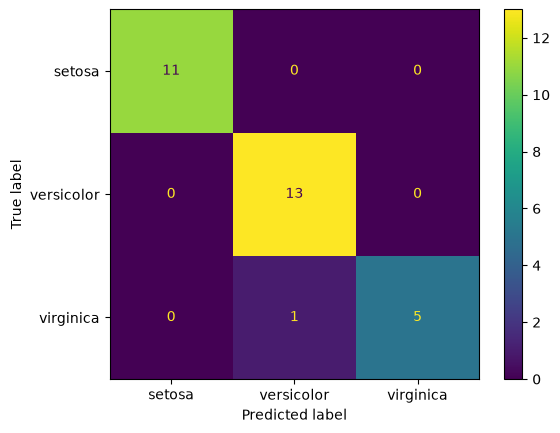

accuracy = 0.967
Wrong flowers: [135]


In [15]:
predicted = model.predict(X_test)
ConfusionMatrixDisplay.from_predictions(y_test, predicted)
plt.show()

print(f"accuracy = {accuracy_score(y_test, predicted):.3f}")
print("Wrong flowers:", list(X_test.index[predicted != y_test]))

The lazy classifier "always the most common species of the test set":

In [16]:
print(y_test.value_counts())
print(f"'always {y_test.value_counts().idxmax()}': accuracy = {y_test.value_counts().max() / len(y_test):.3f}")

species
versicolor    13
setosa        11
virginica      6
Name: count, dtype: int64
'always versicolor': accuracy = 0.433


### 10-fold cross-validation (on the training set)

In [17]:
scores = cross_val_score(GaussianNB(), X_train, y_train, cv=10)
print(scores.round(2))
print(f"mean accuracy = {scores.mean():.3f}")

[1.   0.92 0.83 1.   0.92 1.   1.   1.   0.92 0.92]
mean accuracy = 0.950


## Summary

- Continuous features: no pmf to count. Bayes' rule with a density: $p_{\tilde{y}}(y) f_{\tilde{x}\mid\tilde{y}}(x \mid y)$ plays the role of the joint pmf.
- The naive Bayes assumption is false here (look at the correlations inside virginica), and still 29 of 30 test flowers are right.
- `GaussianNB`: training = means and standard deviations.

**Read more:** Fernandez-Granda, *Probability and Statistics for Data Science*, section 6.3 (Theorem 6.6) and section 6.5. *An Introduction to Statistical Learning, with Python*, section 4.4.4.